In [1]:
import scanpy as sc
import numpy as np
import scprep
from anndata import AnnData
import phate
from phate.cluster import kmeans
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [56]:
import sys
sys.path.append('..')
from dhg import Hypergraph
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.data import HGDataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Dataset
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping
from torch.utils.data import random_split
from pytorch_lightning.loggers import TensorBoardLogger
from hypgs import DATA_DIR
import anndata
import os
import torch
import numpy as np
import phate
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
import scanpy as sc
from sklearn.neighbors import kneighbors_graph
import random 
from torch_geometric.utils.convert import from_networkx
from importlib import reload
from hypgs.models.hsn_pyg import HyperScatteringModule
from torch_geometric.utils.convert import from_networkx
from einops import rearrange
from scipy.spatial import ConvexHull



In [3]:
adata_subset = sc.read_h5ad("merfish_H20.33.001.CX28.MTG.02.007.1.02.02.h5ad", backed='r')

<AxesSubplot:>

<Figure size 1000x1000 with 0 Axes>

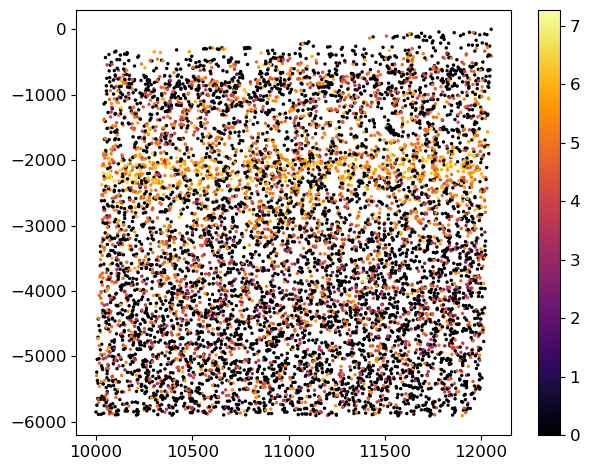

In [4]:
plt.figure(figsize=(10, 10))
scprep.plot.scatter2d(adata_subset.obsm['X_selected_cell_spatial_tiled'], c=adata_subset.X[:, 0].toarray())

<AxesSubplot:>

<Figure size 1000x1000 with 0 Axes>

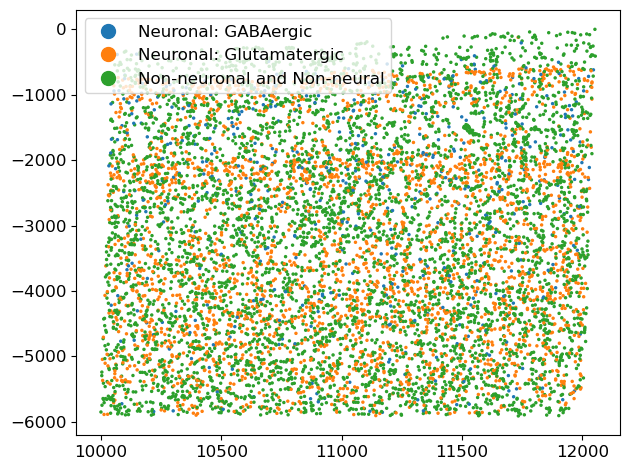

In [5]:
plt.figure(figsize=(10, 10))
scprep.plot.scatter2d(adata_subset.obsm['X_selected_cell_spatial_tiled'], c=adata_subset.obs["Class"])

<AxesSubplot:>

<Figure size 1000x1000 with 0 Axes>

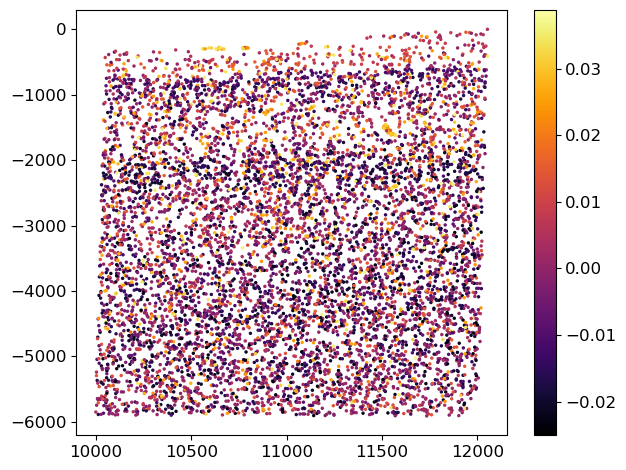

In [6]:
plt.figure(figsize=(10, 10))
scprep.plot.scatter2d(adata_subset.obsm['X_selected_cell_spatial_tiled'], c=adata_subset.obsm['X_phate'][:, 0])

In [22]:
K=10
sparseA = kneighbors_graph(adata_subset.obsm['X_selected_cell_spatial_tiled'], K, mode='connectivity', include_self=False)
A = sparseA.todense()
G = nx.from_numpy_array(A)
# X_cmbn = np.concatenate((adata_subset[:,:].X.toarray(), adata_subset.obsm['X_phate']), axis=1)
X_cmbn = adata_subset[:,:].X.toarray()
data = from_networkx(G)
data.x = torch.tensor(X_cmbn)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, 1)
dataset = HGDataset(original_dataset, to_hg_func)

Converting to hypergraph data: 100%|██████████| 1/1 [00:15<00:00, 15.09s/it]


In [23]:
model = HyperScatteringModule(in_channels=183, 
              trainable_laziness = False,
              trainable_scales = False, 
              activation = None, # just get one layer of wavelet transform 
              fixed_weights=True, 
              normalize='right', 
              reshape=False,
        )

In [24]:
s_nodes, s_edges = model(dataset[0].x.float(), dataset[0].edge_index, hyperedge_attr = dataset[0].edge_attr)

In [25]:
s_nodes.size()

torch.Size([1, 6, 8475, 180])

In [26]:
s_edges.size()

torch.Size([1, 6, 8211, 180])

In [27]:
# f_nodes = out_features[0]
# reverted = rearrange(f_nodes, 'n (w f a) -> a w n f', w=1, f=183, a=6).squeeze().detach().cpu().numpy()

In [28]:
# node_feat = reverted[0, :, 0]

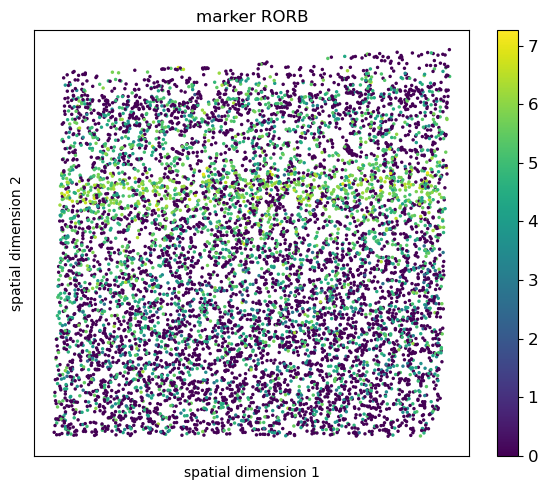

In [111]:
node_feat = adata_subset[:,:].X.toarray()[:, 0]
scprep.plot.scatter2d(adata_subset.obsm['X_selected_cell_spatial_tiled'], c=node_feat, cmap='viridis')
plt.xlabel('spatial dimension 1')
plt.ylabel('spatial dimension 2')
plt.xticks([])
plt.yticks([])
plt.title(f'marker RORB')
plt.show()

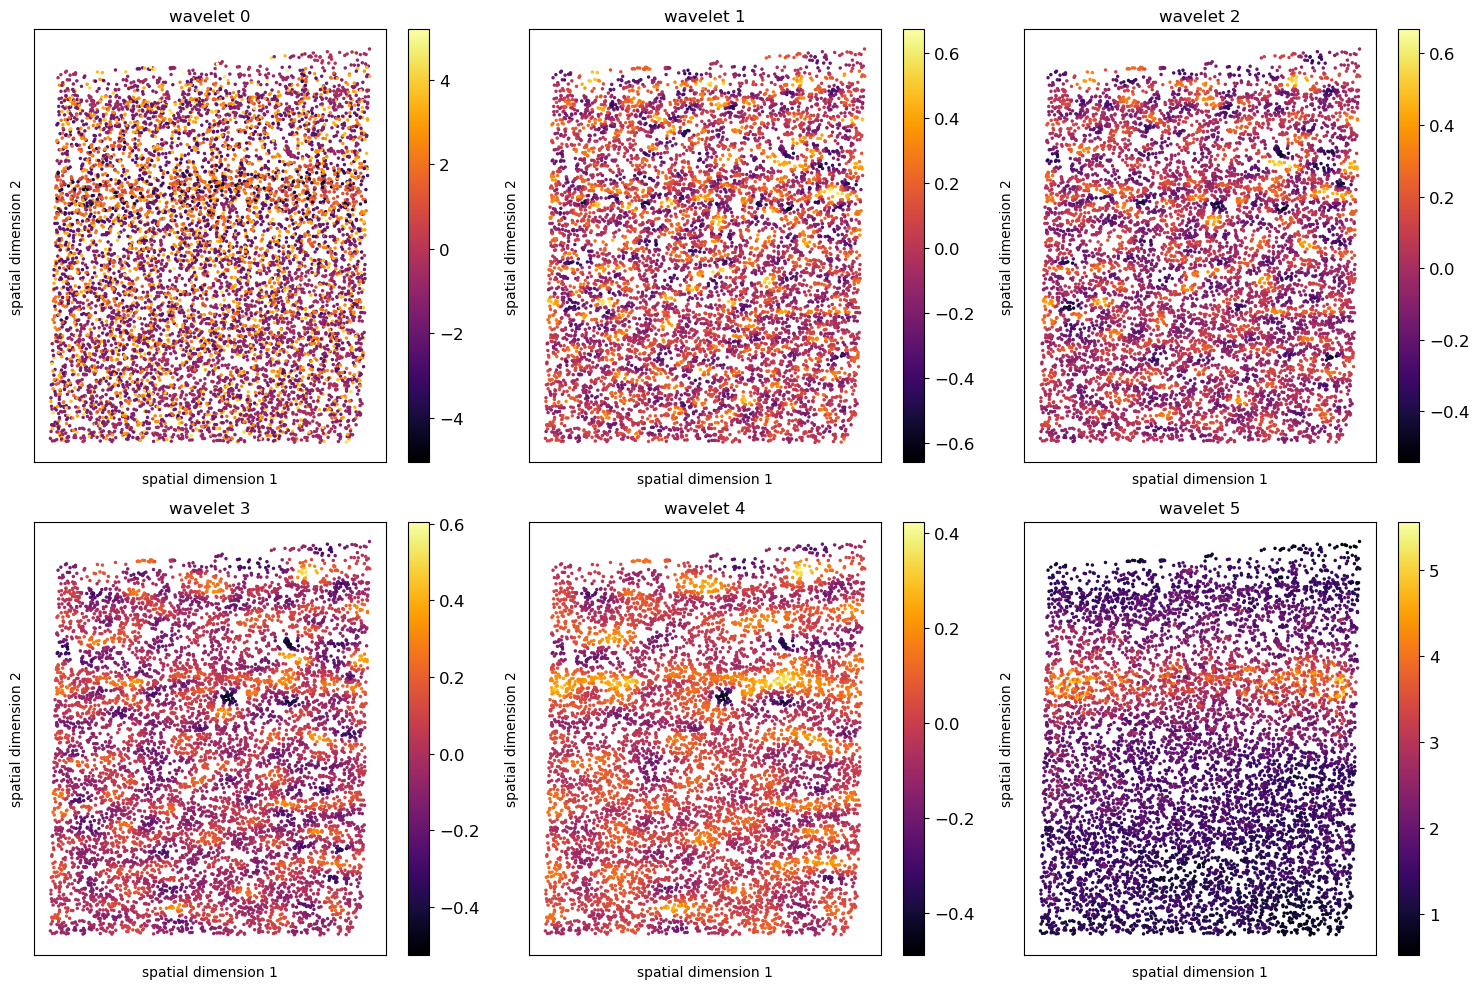

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    node_feat = s_nodes[0,i,:,0].detach().cpu().numpy()
    scprep.plot.scatter2d(adata_subset.obsm['X_selected_cell_spatial_tiled'], c=node_feat, ax=ax)
    ax.set_xlabel('spatial dimension 1')
    ax.set_ylabel('spatial dimension 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'wavelet {i}')

plt.tight_layout()
plt.show()


In [31]:
s_edges[0,i,:,0]

tensor([2.8954, 2.1824, 1.7296,  ..., 3.1367, 2.9321, 1.8707],
       grad_fn=<SelectBackward0>)

In [32]:
wvs = [s_edges[0,i,...].detach().cpu().numpy() for i in range(6)]
wvs_phate = []
phate_ops = []
for i in range(6):
    phate_op = phate.PHATE()
    wv0 = wvs[i]
    wv0_phate = phate_op.fit_transform(wv0)
    wvs_phate.append(wv0_phate)
    phate_ops.append(phate_op)

Calculating PHATE...
  Running PHATE on 8211 observations and 180 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.32 seconds.
    Calculating KNN search...
    Calculated KNN search in 11.76 seconds.
    Calculating affinities...
    Calculated affinities in 0.06 seconds.
  Calculated graph and diffusion operator in 12.16 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.51 seconds.
    Calculating KMeans...
    Calculated KMeans in 6.75 seconds.
  Calculated landmark operator in 8.99 seconds.
  Calculating optimal t...
    Automatically selected t = 46
  Calculated optimal t in 5.60 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 3.69 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 6.26 seconds.
Calculated PHATE in 36.71 seconds.
Calculating PHATE...
  Running PHATE on 8211 observations and 180 variables.
  Calculating graph and diffusion o

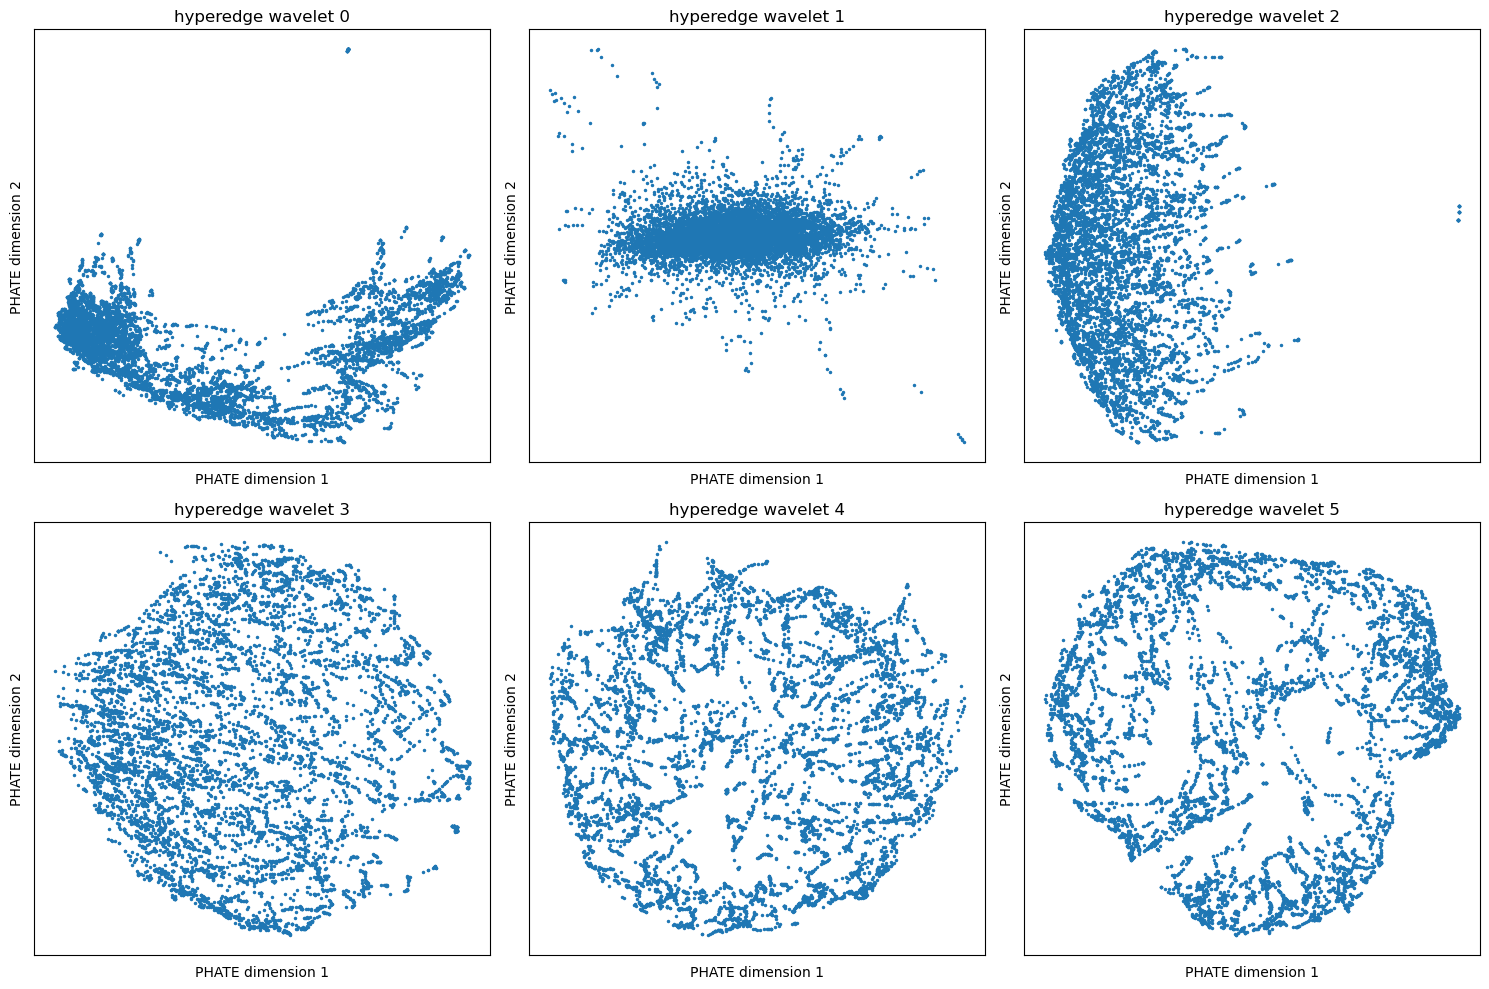

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    wv_phate = wvs_phate[i]
    scprep.plot.scatter2d(wv_phate, ax=ax)
    ax.set_xlabel('PHATE dimension 1')
    ax.set_ylabel('PHATE dimension 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'hyperedge wavelet {i}')

plt.tight_layout()
plt.show()


In [35]:
wv_n_s = [s_nodes[0,i,...].detach().cpu().numpy() for i in range(6)]
wv_n_s_phate = []
phate_ops_n = []
for i in range(6):
    phate_op = phate.PHATE()
    wv_n_0 = wv_n_s[i]
    wv0_phate = phate_op.fit_transform(wv0)
    wvs_phate.append(wv0_phate)
    phate_ops_n.append(phate_op)

Calculating PHATE...
  Running PHATE on 8211 observations and 180 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.34 seconds.
    Calculating KNN search...
    Calculated KNN search in 3.06 seconds.
    Calculating affinities...
    Calculated affinities in 0.05 seconds.
  Calculated graph and diffusion operator in 3.46 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.48 seconds.
    Calculating KMeans...
    Calculated KMeans in 7.58 seconds.
  Calculated landmark operator in 9.25 seconds.
  Calculating optimal t...
    Automatically selected t = 57
  Calculated optimal t in 6.38 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 4.46 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 11.25 seconds.
Calculated PHATE in 34.82 seconds.
Calculating PHATE...
  Running PHATE on 8211 observations and 180 variables.
  Calculating graph and diffusion op

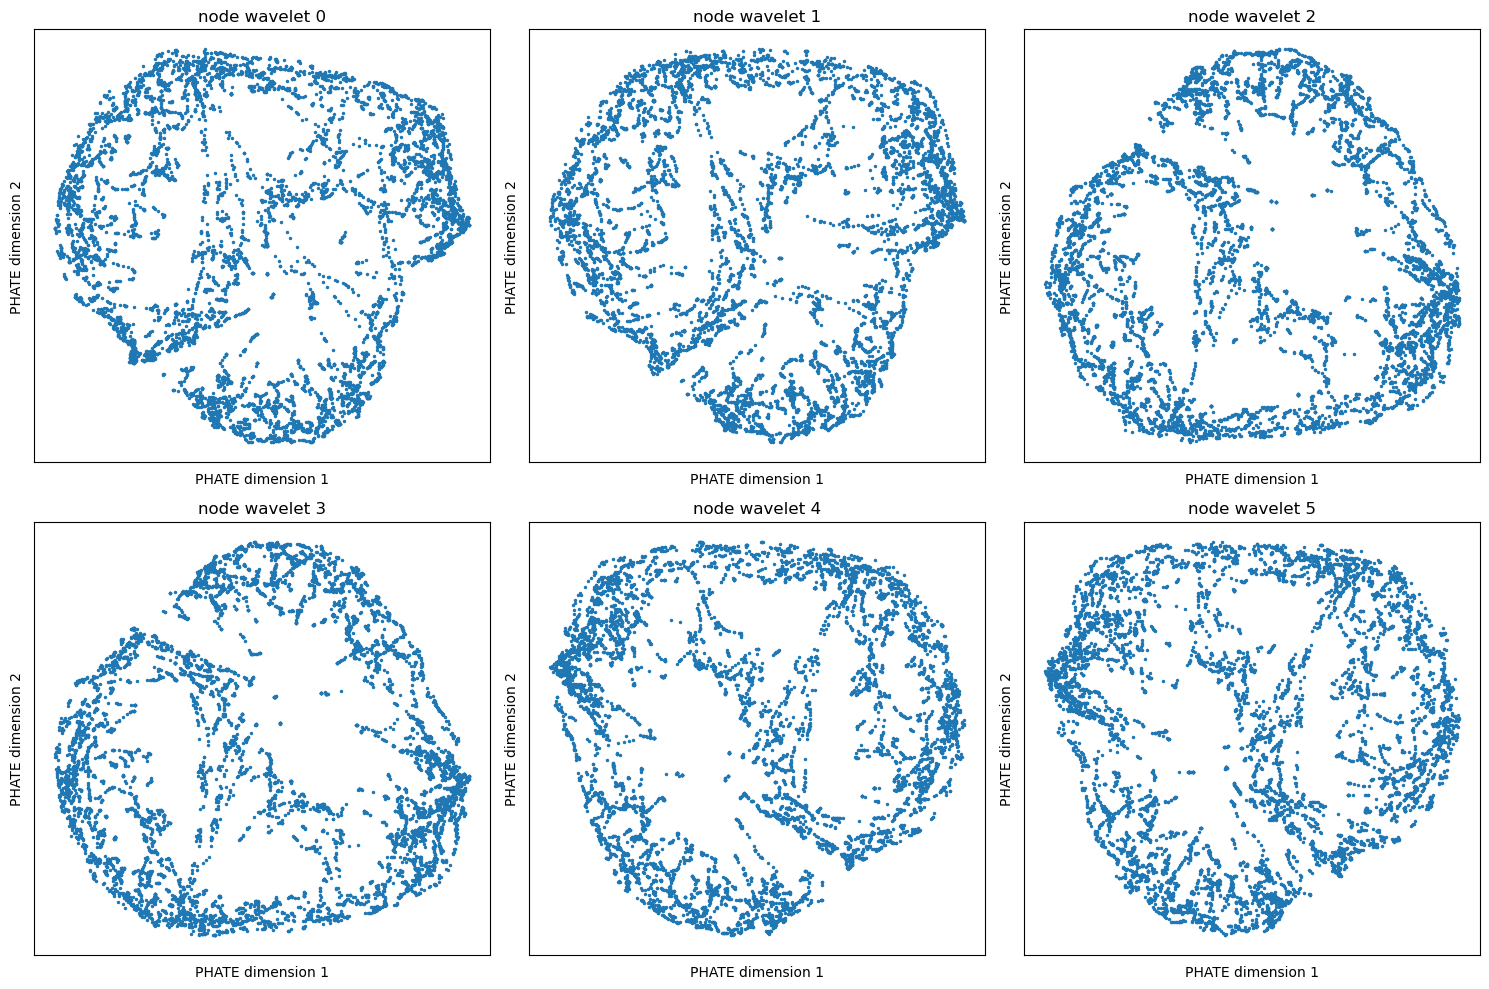

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    wv_phate = wvs_phate[i+6]
    scprep.plot.scatter2d(wv_phate, ax=ax)
    ax.set_xlabel('PHATE dimension 1')
    ax.set_ylabel('PHATE dimension 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'node wavelet {i}')

plt.tight_layout()
plt.show()


In [37]:
wv_n_s_phate

[]

In [73]:
ei = dataset[0].edge_index
coordinates = adata_subset.obsm['X_selected_cell_spatial_tiled']
vals = s_edges[0,0,:,0].detach().cpu().numpy()
eidf = pd.DataFrame(ei.T.numpy(), columns=['node_idx', 'he_idx'])
eidf[['x', 'y']] = coordinates[eidf['node_idx'].values, :]
eidf['value'] = vals[eidf['he_idx'].values.flatten()]

In [ ]:
def get_hyperedge_pos_df(hgdataset, coordinates):
    ei = hgdataset.edge_index
    eidf = pd.DataFrame(ei.T.numpy(), columns=['node_idx', 'he_idx'])
    eidf[['x', 'y']] = coordinates[eidf['node_idx'].values, :]
    return eidf

In [101]:
def get_hyperedge_pos_df(hgdataset, coordinates):
    ei = hgdataset.edge_index
    eidf = pd.DataFrame(ei.T.numpy(), columns=['node_idx', 'he_idx'])
    eidf[['x', 'y']] = coordinates[eidf['node_idx'].values, :]
    return eidf

def enlarge_hull(points, hull, factor=0.1):
    centroid = np.mean(points[hull.vertices, :], axis=0)
    new_vertices = []
    for vertex in points[hull.vertices, :]:
        direction = vertex - centroid
        new_vertex = centroid + (1 + factor) * direction
        new_vertices.append(new_vertex)
    return np.array(new_vertices)

def compute_enlarged_hulls(df):
    enlarged_hulls = []

    for set_index, group in df.groupby('he_idx'):
        points = group[['x', 'y']].values
        hull = ConvexHull(points)
        enlarged_hull = enlarge_hull(points, hull)

        # Store the enlarged hull and the mean value for color coding
        enlarged_hulls.append(enlarged_hull)

    return enlarged_hulls

def plot_hulls(enlarged_hulls, color_values, title='', colormap=plt.cm.viridis, alpha=0.5, ax=None, show_cbar=True):
    if ax is None:
        fig, ax = plt.subplots()

    # Normalize color values
    norm = plt.Normalize(min(color_values), max(color_values))

    for hull, value in zip(enlarged_hulls, color_values):
        color = colormap(norm(value))
        ax.fill(hull[:, 0], hull[:, 1], color=color, alpha=alpha)

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('X Coordinate')
    ax.set_ylabel('Y Coordinate')
    if show_cbar:
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=colormap), ax=ax)
    # ax.show()
    return ax

In [99]:
enlarged_hulls = compute_enlarged_hulls(eidf)

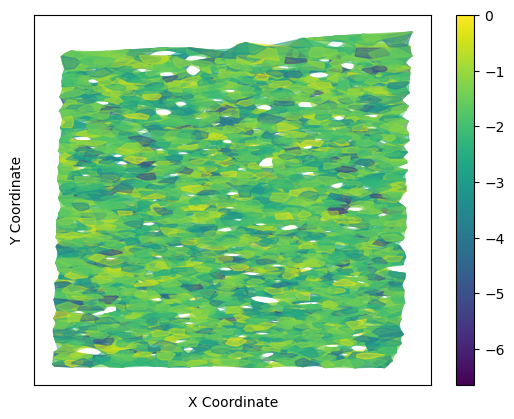

In [102]:
plot_hulls(enlarged_hulls, eidf['value'], colormap=plt.cm.viridis, alpha=0.5)

In [131]:
def plot_wavelets(node_features, edge_features, coordinates, enlarged_hulls):
    fig, axes = plt.subplots(2, 6, figsize=(30, 10))

    for i, axs in enumerate(axes.T):

        scprep.plot.scatter2d(coordinates, c=node_features[:,i], ax=axs[0], cmap='viridis')
        axs[0].set_xticks([])
        axs[0].set_yticks([])
        axs[0].set_title(f'node wavelet {i}')
        plot_hulls(enlarged_hulls, edge_features[:,i], colormap=plt.cm.viridis, alpha=0.5, ax=axs[1])
        axs[1].set_title(f'hyperedge wavelet {i}')

    plt.tight_layout()
    plt.show()


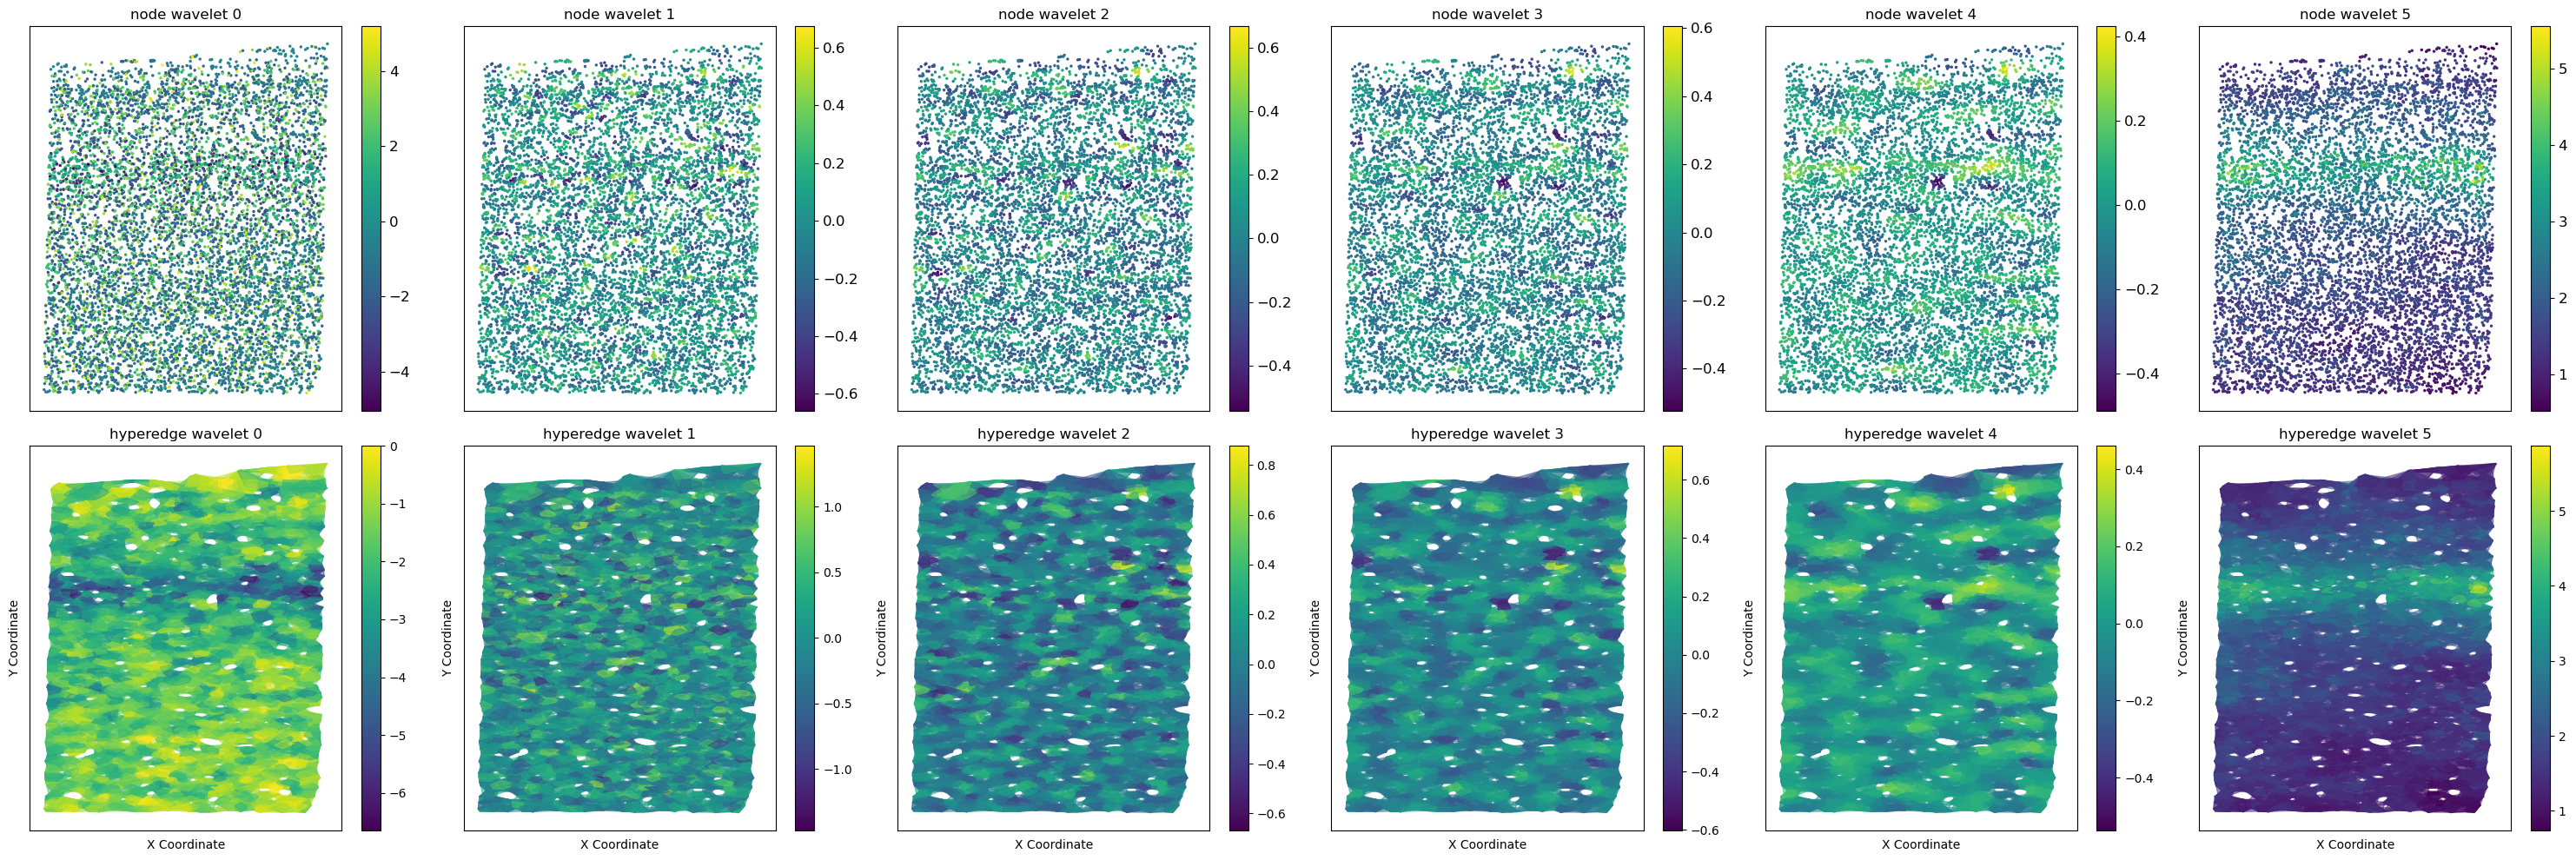

In [132]:
node_feats = s_nodes[0,:,:,0].detach().cpu().numpy().T
edge_feats = s_edges[0,:,:,0].detach().cpu().numpy().T
plot_wavelets(node_feats, edge_feats, coordinates, enlarged_hulls)

In [129]:
edge_feats[:,0]

array([-2.1510463 , -0.07033014, -0.23330235, -0.23362446, -0.20710158,
        2.8954048 ], dtype=float32)